# Deteção de phishing com Machine Learning
## Trabalho individual de Nathan

**Objetivo:** aprender a distinguir sites legítimos de phishing usando as características do dataset indicado.
Este notebook reúne os temas marcados com **M — minimum to apply** no roadmap.
Lê as explicações e executa as células de cima para baixo. Os resultados são calculados pelo código.

**Como usar:** abre no Google Colab, escolhe um ambiente Python com CPU e executa tudo.
O CSV é descarregado automaticamente. Se isso falhar, descarrega o ZIP do Kaggle,
extrai `phishing.csv` e carrega esse ficheiro no painel Ficheiros do Colab.

**Autor:** Nathan. **Turma:** 2ºCIB.

**O que preciso de perceber primeiro:** o **dataset** é a tabela com os exemplos.
Os **modelos** são formas diferentes de aprender com esses mesmos exemplos.
Não precisas de três datasets: treinas três modelos com o mesmo dataset.
Neste trabalho, destaca **Árvore de decisão, Random Forest e XGBoost**.
Os outros modelos mantêm a cobertura dos tópicos M do roadmap.

**O código já faz o treino:** `fit(X_train, y_train)` ensina o modelo; `predict(X_test)`
produz respostas para exemplos reservados. `cross_validate` treina e valida automaticamente
em várias divisões do treino. As métricas comparam as previsões com as respostas reais.

**Para a apresentação atual:** mostra a tabela numérica de validação da secção 8,
a tabela numérica de teste e os gráficos da secção 10 e a conclusão da secção 11.
As tabelas incluem accuracy, precision, recall, F1 e ROC-AUC.
A conversa partilhada sugere pelo menos três modelos nesta fase; não confirma uma alteração formal
dos requisitos do roadmap. Criar um agente fica fora do âmbito desta entrega.

## 1 Entender o problema

Phishing é uma tentativa de enganar pessoas para obter dados, como palavras-passe.
O objetivo é apoiar a identificação de sites suspeitos. O utilizador previsto é alguém que faz triagem de segurança.

- **Entrada:** 30 características já calculadas, como indicadores de HTTPS e de links.
- **Saída:** previsão de phishing ou legítimo.
- **Tipo:** aprendizagem supervisionada, porque os exemplos já têm uma resposta conhecida; classificação binária, porque há duas classes.
- **Critério de escolha:** maior F1 médio na validação. O F1 equilibra precision e recall.
- **Objetivo de negócio:** detetar phishing, acompanhando o recall e os falsos alarmes. Um falso negativo deixa passar phishing; um falso positivo sinaliza um site legítimo.
- **Referência mínima:** comparar com um modelo que prevê sempre a classe mais frequente. Não se promete uma percentagem antes de testar.

É um protótipo académico com dados históricos. Não visita sites nem extrai características a partir de um URL.
Um resultado alto neste ficheiro não demonstra proteção contra ataques atuais.

## 2 Preparar as bibliotecas

`pandas` lê a tabela; `matplotlib` e `seaborn` fazem gráficos; `scikit-learn` e `xgboost` treinam modelos.
Esta célula instala o que falta no ambiente onde estiveres a executar o notebook.

In [1]:
%pip -q install pandas numpy matplotlib seaborn scikit-learn xgboost

Bibliotecas instaladas; ambiente de execução verificado.


In [2]:
from pathlib import Path
from io import BytesIO
from urllib.request import urlopen
import zipfile
import hashlib
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay,
                             confusion_matrix, classification_report)
from xgboost import XGBClassifier

SEED = 42
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 35)

## 3 Ler e conhecer os dados

Fonte: [Kaggle — Phishing website Detector](https://www.kaggle.com/datasets/eswarchandt/phishing-website-detector).
Na versão verificada, o CSV tem **11 054 linhas, 30 características, um índice e a coluna `class`**.
O ficheiro TXT tem uma linha adicional; usamos apenas o CSV para não misturar versões.

Os valores das características são códigos, geralmente `-1`, `0` e `1`, e não medidas como centímetros.
`Index` identifica linhas e não deve ser usado para prever a resposta.
`class` é o resultado conhecido. Uso a convenção `-1 = phishing` e `1 = legítimo`.
No modelo converto para **1 = phishing** e **0 = legítimo** para que as métricas positivas meçam phishing.

Na preparação deste trabalho, as 31 colunas de dados do CSV foram comparadas com o ficheiro
`Training Dataset.arff` do [UCI Phishing Websites](https://archive.ics.uci.edu/dataset/327/phishing+websites):
são iguais, na mesma ordem, depois de excluir a primeira linha do UCI e o índice do CSV.

In [3]:
ficheiro = Path('phishing.csv')
if not ficheiro.exists():
    url = 'https://www.kaggle.com/api/v1/datasets/download/eswarchandt/phishing-website-detector'
    try:
        with urlopen(url, timeout=90) as resposta:
            with zipfile.ZipFile(BytesIO(resposta.read())) as arquivo:
                ficheiro.write_bytes(arquivo.read('phishing.csv'))
    except Exception as erro:
        raise RuntimeError('Carrega phishing.csv no painel Ficheiros e volta a executar esta célula.') from erro

original = pd.read_csv(ficheiro)
print('Linhas e colunas:', original.shape)
print('SHA256 do CSV:', hashlib.sha256(ficheiro.read_bytes()).hexdigest())
display(original.head())
display(original['class'].value_counts().rename('Quantidade'))
print('Valores em falta:', original.isna().sum().sum())

Linhas e colunas: (11054, 32)
SHA256 do CSV: 96d48b5c9e957e2dc06f880b2161476da192f814f74332cfd2e3d61a35309dc3


,Index,UsingIP,LongURL,ShortURL,Symbol@,Redirecting//,PrefixSuffix-,SubDomains,HTTPS,DomainRegLen,Favicon,NonStdPort,HTTPSDomainURL,RequestURL,AnchorURL,LinksInScriptTags,ServerFormHandler,InfoEmail,AbnormalURL,WebsiteForwarding,StatusBarCust,DisableRightClick,UsingPopupWindow,IframeRedirection,AgeofDomain,DNSRecording,WebsiteTraffic,PageRank,GoogleIndex,LinksPointingToPage,StatsReport,class
0,0,1,1,1,1,1,-1,0,1,-1,1,1,-1,1,0,-1,-1,1,1,0,1,1,1,1,-1,-1,0,-1,1,1,1,-1
1,1,1,0,1,1,1,-1,-1,-1,-1,1,1,-1,1,0,-1,-1,-1,-1,0,1,1,1,1,1,-1,1,-1,1,0,-1,-1
2,2,1,0,1,1,1,-1,-1,-1,1,1,1,-1,-1,0,0,-1,1,1,0,1,1,1,1,-1,-1,1,-1,1,-1,1,-1
3,3,1,0,-1,1,1,-1,1,1,-1,1,1,1,1,0,0,-1,1,1,0,-1,1,-1,1,-1,-1,0,-1,1,1,1,1
4,4,-1,0,-1,1,-1,-1,1,1,-1,1,1,-1,1,0,0,-1,-1,-1,0,1,1,1,1,1,1,1,-1,1,-1,-1,1


class
 1    6157
-1    4897
Name: Quantidade, dtype: int64

Valores em falta: 0


## 4 Limpar os dados e separar o teste

Retiro `Index` e cópias de linhas iguais. Depois reservo aproximadamente 20% para teste.
Há combinações de características iguais com respostas diferentes. Mantenho esses casos,
mas coloco cada combinação inteira num só conjunto através de grupos.
Assim, o teste não contém uma cópia das características de uma linha de treino.

**Valores em falta:** esta versão não tem; uso um preenchimento pela moda na pipeline,
aprendido apenas no treino. **Outliers:** `-1` e `1` são códigos válidos, não extremos a apagar.
Verifico valores fora de `{-1, 0, 1}` em vez de aplicar uma regra de outliers a códigos.

A remoção de cópias muda a frequência dos padrões. Os resultados passam a descrever sobretudo padrões distintos.
A exploração detalhada será feita no treino, mantendo o teste reservado até ao fim.

In [4]:
dados = original.drop(columns=['Index']).copy()
assert set(dados['class'].dropna().unique()) == {-1, 1}, 'Verificar os códigos da resposta.'
assert not dados['class'].isna().any(), 'Há respostas em falta.'
n_duplicadas = int(dados.duplicated().sum())
dados = dados.drop_duplicates().reset_index(drop=True)
X = dados.drop(columns='class')
y = dados['class'].map({-1: 1, 1: 0}).rename('phishing')

invalidos = (~X.isin([-1, 0, 1]) & X.notna()).sum()
print('Valores fora dos códigos esperados:', int(invalidos.sum()))
assert invalidos.sum() == 0, 'Rever os valores inesperados antes de continuar.'

grupos = pd.util.hash_pandas_object(X, index=False)
conflitos = int(y.groupby(grupos).nunique().gt(1).sum())
divisao = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
treino, teste = next(divisao.split(X, y, groups=grupos))
X_train, X_test = X.iloc[treino], X.iloc[teste]
y_train, y_test = y.iloc[treino], y.iloc[teste]
g_train, g_test = grupos.iloc[treino], grupos.iloc[teste]
assert set(g_train).isdisjoint(set(g_test))
assert y_train.nunique() == y_test.nunique() == 2

print('Cópias removidas:', n_duplicadas)
print('Linhas após limpeza:', len(dados))
print('Grupos com respostas contraditórias:', conflitos)
print('Treino:', len(X_train), '| Teste reservado:', len(X_test))

Valores fora dos códigos esperados: 0
Cópias removidas: 5205
Linhas após limpeza: 5849
Grupos com respostas contraditórias: 64
Treino: 4682 | Teste reservado: 1167


## 5 Explorar os dados

**Univariada:** estudar uma variável de cada vez. Mostro frequências e estatísticas.
As médias dos códigos servem para descrição numérica; não são médias de comprimentos reais.

,UsingIP,LongURL,ShortURL,Symbol@,Redirecting//,PrefixSuffix-,SubDomains,HTTPS,DomainRegLen,Favicon,NonStdPort,HTTPSDomainURL,RequestURL,AnchorURL,LinksInScriptTags,ServerFormHandler,InfoEmail,AbnormalURL,WebsiteForwarding,StatusBarCust,DisableRightClick,UsingPopupWindow,IframeRedirection,AgeofDomain,DNSRecording,WebsiteTraffic,PageRank,GoogleIndex,LinksPointingToPage,StatsReport
count,4682.00,4682.00,4682.00,4682.00,4682.00,4682.00,4682.00,4682.00,4682.00,4682.00,4682.00,4682.00,4682.00,4682.00,4682.00,4682.00,4682.00,4682.00,4682.00,4682.00,4682.00,4682.00,4682.00,4682.00,4682.00,4682.00,4682.00,4682.00,4682.00,4682.00
mean,0.14,-0.62,0.71,0.59,0.71,-0.76,0.07,0.15,-0.31,0.58,0.68,0.65,0.13,-0.14,-0.15,-0.59,0.57,0.67,0.14,0.72,0.90,0.57,0.79,0.01,0.46,0.24,-0.42,0.66,0.35,0.70
std,0.99,0.77,0.70,0.81,0.70,0.65,0.81,0.93,0.95,0.81,0.73,0.76,0.99,0.72,0.78,0.75,0.82,0.74,0.34,0.69,0.43,0.82,0.62,1.00,0.89,0.82,0.91,0.75,0.58,0.71
min,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,0.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00
25%,-1.00,-1.00,1.00,1.00,1.00,-1.00,-1.00,-1.00,-1.00,1.00,1.00,1.00,-1.00,-1.00,-1.00,-1.00,1.00,1.00,0.00,1.00,1.00,1.00,1.00,-1.00,-1.00,0.00,-1.00,1.00,0.00,1.00
50%,1.00,-1.00,1.00,1.00,1.00,-1.00,0.00,1.00,-1.00,1.00,1.00,1.00,1.00,0.00,0.00,-1.00,1.00,1.00,0.00,1.00,1.00,1.00,1.00,1.00,1.00,0.00,-1.00,1.00,0.00,1.00
75%,1.00,-1.00,1.00,1.00,1.00,-1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,0.00,0.00,-1.00,1.00,1.00,0.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
max,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


,tipo,valores_distintos,em_falta
UsingIP,int64,2,0
LongURL,int64,3,0
ShortURL,int64,2,0
Symbol@,int64,2,0
Redirecting//,int64,2,0
PrefixSuffix-,int64,2,0
SubDomains,int64,3,0
HTTPS,int64,3,0
DomainRegLen,int64,2,0
Favicon,int64,2,0


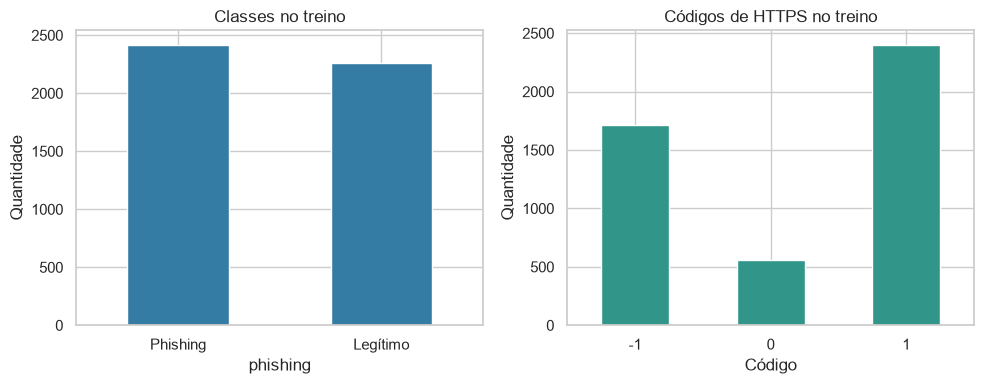

In [5]:
display(X_train.describe().round(2))
display(pd.DataFrame({'tipo': X_train.dtypes.astype(str),
                      'valores_distintos': X_train.nunique(),
                      'em_falta': X_train.isna().sum()}))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
y_train.map({0: 'Legítimo', 1: 'Phishing'}).value_counts().plot.bar(ax=axes[0], rot=0, color='#357ca5')
axes[0].set(title='Classes no treino', ylabel='Quantidade')
X_train['HTTPS'].value_counts().sort_index().plot.bar(ax=axes[1], rot=0, color='#31958a')
axes[1].set(title='Códigos de HTTPS no treino', xlabel='Código', ylabel='Quantidade')
plt.tight_layout()
plt.show()

**Bivariada:** relacionar duas variáveis. Aqui observo a proporção de phishing em cada código de HTTPS.
**Multivariada:** observar várias variáveis em conjunto. Cruzo HTTPS, AnchorURL e a classe.
Em cada combinação, a média de `phishing` é a proporção de exemplos com phishing.

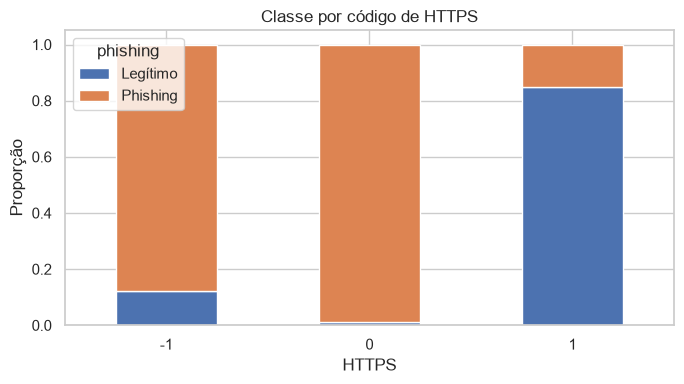

count   mean
HTTPS AnchorURL              
-1    -1           987  1.000
       0           608  0.757
       1           122  0.475
 0    -1           454  1.000
       0            88  0.920
       1            20  1.000
 1    -1           142  0.887
       0          1453  0.153
       1           808  0.014

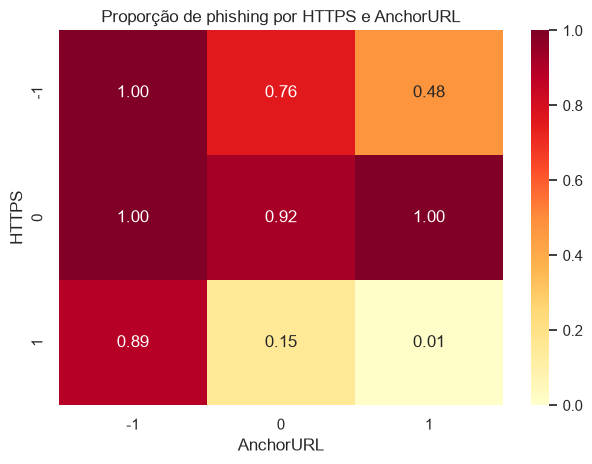

In [6]:
eda = X_train.copy()
eda['phishing'] = y_train
tabela = pd.crosstab(eda['HTTPS'], eda['phishing'], normalize='index')
tabela = tabela.rename(columns={0: 'Legítimo', 1: 'Phishing'})
tabela.plot.bar(stacked=True, figsize=(7, 4), rot=0)
plt.title('Classe por código de HTTPS')
plt.ylabel('Proporção')
plt.tight_layout()
plt.show()

display(eda.groupby(['HTTPS', 'AnchorURL'])['phishing'].agg(['count', 'mean']).round(3))
multi = eda.pivot_table(index='HTTPS', columns='AnchorURL', values='phishing', aggfunc='mean')
sns.heatmap(multi, annot=True, fmt='.2f', vmin=0, vmax=1, cmap='YlOrRd')
plt.title('Proporção de phishing por HTTPS e AnchorURL')
plt.tight_layout()
plt.show()

**Correlação:** Pearson mede associação linear; Spearman mede associação entre posições ordenadas.
Ambos variam de -1 a 1. Perto de 0 há pouca associação daquele tipo.
Os códigos destas variáveis limitam a interpretação; correlação não prova uma relação de causa e efeito.

,Pearson,Spearman
UsingIP,-0.093,-0.093
LongURL,-0.042,-0.038
ShortURL,0.074,0.074
Symbol@,-0.030,-0.030
Redirecting//,0.036,0.036
PrefixSuffix-,-0.383,-0.383
SubDomains,-0.295,-0.302
HTTPS,-0.692,-0.705
DomainRegLen,0.218,0.218
Favicon,0.020,0.020


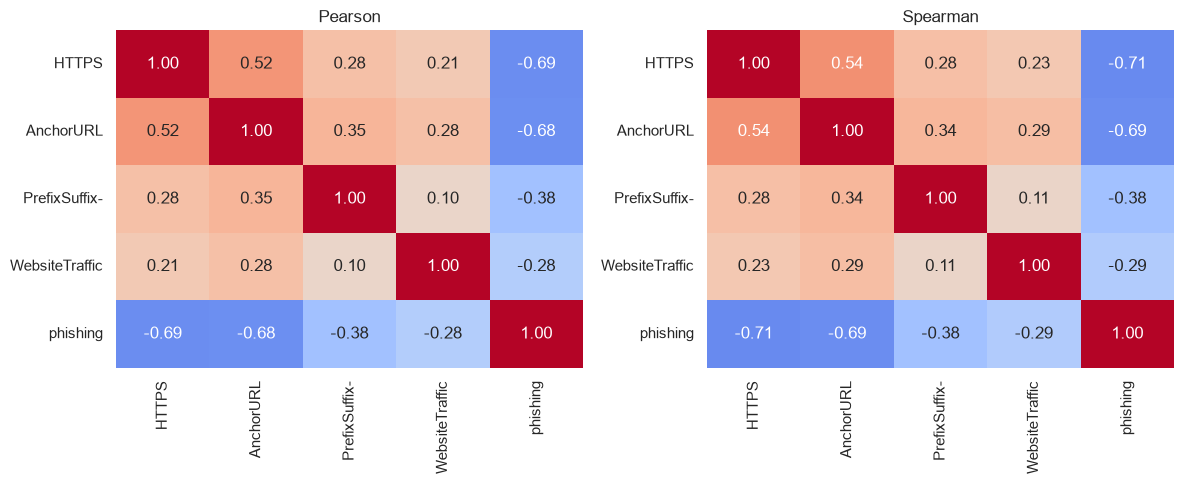

Maior associação absoluta com phishing, no treino: HTTPS
Pearson: -0.692


In [7]:
pearson = eda.corr(method='pearson')
spearman = eda.corr(method='spearman')
correlacoes = pd.DataFrame({'Pearson': pearson['phishing'], 'Spearman': spearman['phishing']}).drop(index='phishing')
display(correlacoes.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
colunas = ['HTTPS', 'AnchorURL', 'PrefixSuffix-', 'WebsiteTraffic', 'phishing']
for ax, matriz, nome in zip(axes, [pearson, spearman], ['Pearson', 'Spearman']):
    sns.heatmap(matriz.loc[colunas, colunas], annot=True, fmt='.2f', cmap='coolwarm',
                vmin=-1, vmax=1, ax=ax, cbar=False)
    ax.set_title(nome)
plt.tight_layout()
plt.show()

mais_associada = correlacoes['Pearson'].abs().idxmax()
print('Maior associação absoluta com phishing, no treino:', mais_associada)
print('Pearson:', round(correlacoes.loc[mais_associada, 'Pearson'], 3))

## 6 Preparação para os modelos

**Desequilíbrio:** contar as classes antes de decidir um tratamento. Para este exercício,
uma razão até 1,5 entre maior e menor classe é considerada ligeira; é uma regra prática escolhida para o projeto.
Uso F1 e métricas por classe. No ajuste do Random Forest também comparo `class_weight='balanced'`
com a ausência de pesos. Não é necessário gerar exemplos artificiais.

**Scaling:** `StandardScaler` centra e ajusta a escala das colunas. É útil para regressão logística,
KNN e SVM. Embora os códigos já estejam entre -1 e 1, as frequências e os desvios variam.
**Pipeline:** encadeia preenchimento, scaling e modelo, aprendendo a preparação só nos dados de treino de cada divisão.
Para simplificar, mantenho as 30 características; feature selection e feature engineering não estão marcados com M.

In [8]:
contagens = y_train.value_counts().sort_index()
display(pd.DataFrame({'quantidade': contagens, 'percentagem': 100 * contagens / len(y_train)}).round(2))
razao = contagens.max() / contagens.min()
print(f'Razão entre classes: {razao:.2f}')
print('Desequilíbrio ligeiro pela regra escolhida.' if razao <= 1.5 else 'Rever o tratamento do desequilíbrio.')

def preparar(modelo, escalar=False):
    passos = [('imputer', SimpleImputer(strategy='most_frequent'))]
    if escalar:
        passos.append(('scaler', StandardScaler()))
    passos.append(('model', modelo))
    return Pipeline(passos)

,quantidade,percentagem
phishing,,
0,2262,48.31
1,2420,51.69


Razão entre classes: 1.07
Desequilíbrio ligeiro pela regra escolhida.


## 7 Modelos explicados numa frase

| Modelo ou conceito | Explicação simples |
|---|---|
| Regressão linear | Prevê uma quantidade contínua, como um preço. Está no roadmap, mas não é o classificador deste projeto. Exemplo didático abaixo. |
| Regressão logística | Aprende uma probabilidade para cada classe. Apesar do nome, serve para classificação. |
| Árvore de decisão | Faz uma sequência de perguntas para chegar a uma classe. |
| Tipos de árvores | ID3 usa ganho de informação; C4.5 estende ID3; CART faz divisões binárias e permite classificação ou regressão. O scikit-learn usa uma versão de CART. |
| KNN | Decide a partir dos exemplos mais próximos. |
| Naive Bayes | Combina probabilidades assumindo independência das características dada a classe. Uso GaussianNB como referência simples; a hipótese normal não descreve bem todos estes códigos. |
| SVM | Procura uma fronteira que separa as classes com boa margem; uso kernel RBF. |
| Ensemble | Junta vários modelos. Bagging treina modelos com amostras diferentes; boosting acrescenta modelos para corrigir erros anteriores. |
| Gradient Boosting | Adiciona árvores em sequência para melhorar as previsões. |
| XGBoost | Uma implementação eficiente de boosting com regularização. |
| Random Forest | Combina várias árvores com amostragem de linhas e características e agrega as previsões. |

O Dummy é apenas a referência que prevê a classe mais frequente.

In [9]:
# Exemplo fictício de regressão linear, separado dos dados de phishing.
# Entrada: horas de estudo. Saída: pontuação contínua inventada.
exemplo_linear = LinearRegression().fit([[1], [2], [3], [4]], [2, 4, 6, 8])
print('Previsão didática para 5 horas:', exemplo_linear.predict([[5]])[0])

Previsão didática para 5 horas: 10.0


## 8 Comparar os classificadores

Divido apenas o treino em três partes para validação cruzada. Cada modelo aprende com duas partes
e é avaliado na terceira, repetindo três vezes. Os grupos impedem que características repetidas atravessem as divisões.
O teste continua guardado. Ordeno por **F1 de validação**, não pela pontuação de treino.

Dummy concluído
Regressão logística concluído


Árvore de decisão concluído


KNN concluído
Naive Bayes concluído


SVM concluído


Gradient Boosting concluído


XGBoost concluído


Random Forest concluído
VALIDAÇÃO — média de 3 divisões; valores entre 0 e 1


,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC,F1 treino,Desvio F1
0,Random Forest,0.9496,0.9539,0.9483,0.9511,0.9909,0.9888,0.0031
1,Gradient Boosting,0.9408,0.9479,0.9372,0.9424,0.9875,0.9502,0.0036
2,XGBoost,0.9387,0.9462,0.9347,0.9403,0.9870,0.9483,0.0044
3,SVM,0.9374,0.9482,0.9297,0.9389,0.9813,0.9521,0.0044
4,Regressão logística,0.9214,0.9304,0.9165,0.9234,0.9759,0.9245,0.0065
5,KNN,0.9193,0.9154,0.9298,0.9225,0.9717,0.9484,0.0068
6,Árvore de decisão,0.9077,0.9327,0.8868,0.9084,0.9694,0.9139,0.0062
7,Naive Bayes,0.6542,0.5992,0.9996,0.7493,0.9665,0.7494,0.0007
8,Dummy,0.5169,0.5169,1.0000,0.6815,0.5000,0.6815,0.0001


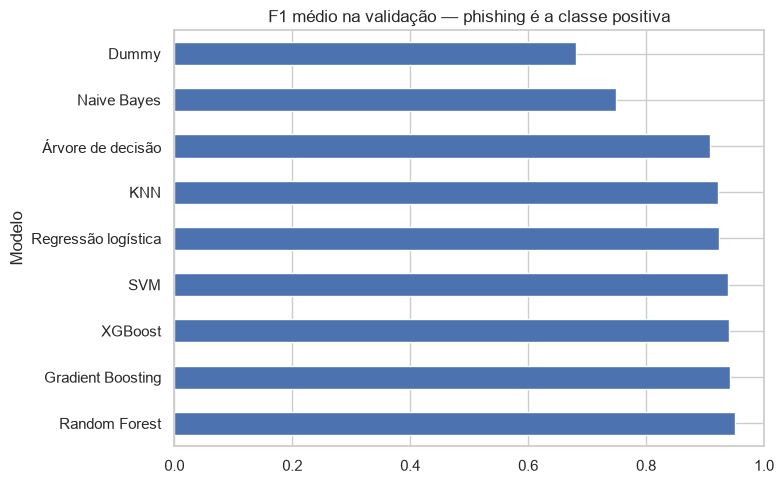

In [10]:
modelos = {
    'Dummy': preparar(DummyClassifier(strategy='most_frequent')),
    'Regressão logística': preparar(LogisticRegression(max_iter=1000, random_state=SEED), True),
    'Árvore de decisão': preparar(DecisionTreeClassifier(max_depth=5, random_state=SEED)),
    'KNN': preparar(KNeighborsClassifier(n_neighbors=5), True),
    'Naive Bayes': preparar(GaussianNB()),
    'SVM': preparar(SVC(kernel='rbf', C=1), True),
    'Gradient Boosting': preparar(GradientBoostingClassifier(n_estimators=100, random_state=SEED)),
    'XGBoost': preparar(XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.1,
                                    eval_metric='logloss', random_state=SEED, n_jobs=2)),
    'Random Forest': preparar(RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=2)),
}

cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
divisoes_cv = list(cv.split(X_train, y_train, groups=g_train))
for a, b in divisoes_cv:
    assert set(g_train.iloc[a]).isdisjoint(set(g_train.iloc[b]))

resultados = []
for nome, modelo in modelos.items():
    scores = cross_validate(modelo, X_train, y_train, cv=divisoes_cv,
                            scoring=['accuracy', 'precision', 'recall', 'f1', 'roc_auc'],
                            return_train_score=True, error_score='raise', n_jobs=1)
    resultados.append({
        'Modelo': nome,
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1': scores['test_f1'].mean(),
        'ROC-AUC': scores['test_roc_auc'].mean(),
        'F1 treino': scores['train_f1'].mean(),
        'Desvio F1': scores['test_f1'].std(),
    })
    print(nome, 'concluído')
comparacao = pd.DataFrame(resultados).sort_values('F1', ascending=False).reset_index(drop=True)
print('VALIDAÇÃO — média de 3 divisões; valores entre 0 e 1')
display(comparacao.round(4))
comparacao.plot.barh(x='Modelo', y='F1', legend=False, figsize=(8, 5), xlim=(0, 1))
plt.title('F1 médio na validação — phishing é a classe positiva')
plt.tight_layout()
plt.show()

## 9 Ajustar parâmetros e observar overfitting

Um hiperparâmetro é uma escolha feita antes do treino, como a profundidade de uma árvore.
Testo oito combinações simples no Random Forest: profundidade, mínimo de exemplos por folha e pesos das classes.
`GridSearchCV` compara-as com as mesmas três divisões de treino. Não usa o teste.

**Overfitting:** resultado muito bom no treino, mas pior na validação.
**Underfitting:** modelo demasiado simples, com resultados fracos em ambos.
Uma diferença entre treino e validação é um sinal a investigar, não uma prova isolada.

In [11]:
pesquisa = GridSearchCV(
    modelos['Random Forest'],
    param_grid={'model__max_depth': [8, None],
                'model__min_samples_leaf': [1, 3],
                'model__class_weight': [None, 'balanced']},
    scoring='f1', cv=divisoes_cv, n_jobs=1, return_train_score=True, error_score='raise'
)
pesquisa.fit(X_train, y_train)
print('Melhores parâmetros do Random Forest:', pesquisa.best_params_)
print('F1 de validação do Random Forest ajustado:', round(pesquisa.best_score_, 4))

# Escolher usando só a validação. Em empate, manter o modelo inicial.
nome_final = comparacao.iloc[0]['Modelo']
modelo_final = clone(modelos[nome_final])
f1_validacao = float(comparacao.iloc[0]['F1'])
if pesquisa.best_score_ > f1_validacao:
    nome_final = 'Random Forest ajustado'
    modelo_final = clone(pesquisa.best_estimator_)
    f1_validacao = float(pesquisa.best_score_)
modelo_final.fit(X_train, y_train)
print('Modelo escolhido:', nome_final)

diagnostico = comparacao[['Modelo', 'F1 treino', 'F1']].copy()
diagnostico['Diferença'] = diagnostico['F1 treino'] - diagnostico['F1']
display(diagnostico.round(4))

# Mesma família, três complexidades, para visualizar a diferença.
linhas = []
for profundidade in [1, 5, None]:
    arvore = preparar(DecisionTreeClassifier(max_depth=profundidade, random_state=SEED))
    s = cross_validate(arvore, X_train, y_train, cv=divisoes_cv,
                       scoring='f1', return_train_score=True, error_score='raise')
    linhas.append({'Profundidade': str(profundidade), 'F1 treino': s['train_score'].mean(),
                   'F1 validação': s['test_score'].mean()})
display(pd.DataFrame(linhas).round(4))

Melhores parâmetros do Random Forest: {'model__class_weight': None, 'model__max_depth': None, 'model__min_samples_leaf': 1}
F1 de validação do Random Forest ajustado: 0.9511


Modelo escolhido: Random Forest


,Modelo,F1 treino,F1,Diferença
0,Random Forest,0.9888,0.9511,0.0377
1,Gradient Boosting,0.9502,0.9424,0.0077
2,XGBoost,0.9483,0.9403,0.0080
3,SVM,0.9521,0.9389,0.0132
4,Regressão logística,0.9245,0.9234,0.0011
5,KNN,0.9484,0.9225,0.0259
6,Árvore de decisão,0.9139,0.9084,0.0055
7,Naive Bayes,0.7494,0.7493,0.0002
8,Dummy,0.6815,0.6815,0.0000


,Profundidade,F1 treino,F1 validação
0,1,0.8768,0.8768
1,5,0.9139,0.9084
2,None,0.9887,0.9258


## 10 Comparar os modelos no teste reservado

- **Accuracy:** proporção de previsões certas no total.
- **Precision:** dos sites sinalizados como phishing, quantos são mesmo phishing.
- **Recall:** de todo o phishing existente, quanto foi detetado.
- **F1:** equilíbrio entre precision e recall.
- **Matriz de confusão:** mostra acertos, falsos alarmes e phishing que passou despercebido.
- **ROC e AUC:** mostram a capacidade de separar as classes ao variar o limiar; AUC de 0,5 corresponde à referência aleatória e 1 à separação perfeita.

Uso probabilidades ou scores contínuos para AUC, não as classes já arredondadas.
Todos os modelos são treinados com o mesmo treino e avaliados no mesmo teste.
A tabela de teste permite comparar os resultados finais, mas o modelo escolhido na secção 9
fica fixo: não volto a escolher modelos ou parâmetros com base neste teste.
As curvas ROC destacam os três modelos da conversa. Os valores das tabelas vão de 0 a 1:
por exemplo, `0.96` equivale a `96%`. Precision, recall e F1 referem-se à classe phishing.

TESTE — três modelos principais; valores entre 0 e 1


,Accuracy,Precision,Recall,F1,ROC-AUC
Modelo,,,,,
Árvore de decisão,0.9237,0.9279,0.9232,0.9255,0.9792
Random Forest,0.9623,0.9680,0.9583,0.9631,0.9946
XGBoost,0.9554,0.9612,0.9516,0.9564,0.9919


TESTE — todos os modelos do roadmap e a referência Dummy


,Accuracy,Precision,Recall,F1,ROC-AUC
Modelo,,,,,
Dummy,0.5133,0.5133,1.0000,0.6784,0.5000
Regressão logística,0.9160,0.9253,0.9098,0.9175,0.9775
Árvore de decisão,0.9237,0.9279,0.9232,0.9255,0.9792
KNN,0.9289,0.9216,0.9416,0.9315,0.9793
Naive Bayes,0.6444,0.5907,1.0000,0.7427,0.9711
SVM,0.9383,0.9520,0.9265,0.9391,0.9859
Gradient Boosting,0.9537,0.9611,0.9482,0.9546,0.9915
XGBoost,0.9554,0.9612,0.9516,0.9564,0.9919
Random Forest,0.9623,0.9680,0.9583,0.9631,0.9946


Modelo já escolhido pela validação: Random Forest


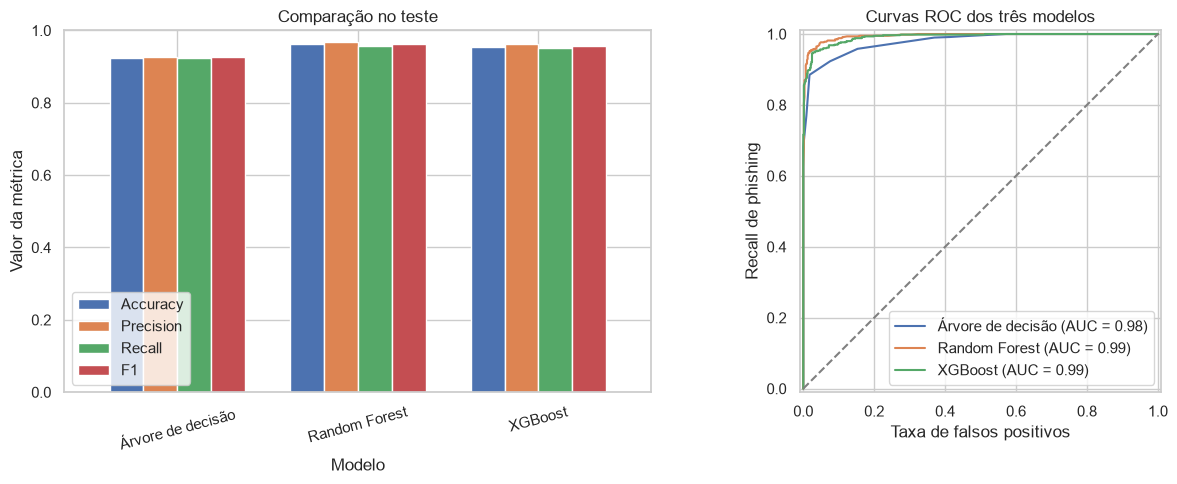

              precision    recall  f1-score   support

    Legítimo       0.96      0.97      0.96       568
    Phishing       0.97      0.96      0.96       599

    accuracy                           0.96      1167
   macro avg       0.96      0.96      0.96      1167
weighted avg       0.96      0.96      0.96      1167



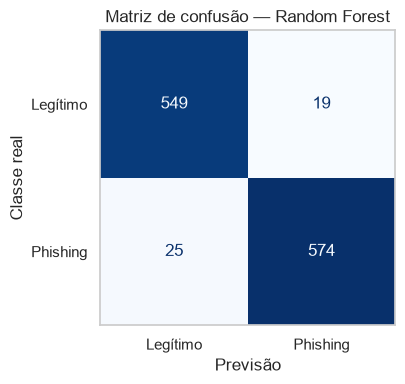

Phishing detetado: 574; phishing não detetado: 25; falsos alarmes: 19; legítimos corretos: 549.


In [12]:
# Treinar todos os modelos no mesmo treino e recolher as cinco métricas no teste.
linhas_teste = []
previsoes_teste = {}
scores_teste = {}
candidatos = dict(modelos)
if nome_final not in candidatos:
    candidatos[nome_final] = modelo_final

for nome, pipeline in candidatos.items():
    treinado = modelo_final if nome == nome_final else clone(pipeline).fit(X_train, y_train)
    pred = treinado.predict(X_test)
    if hasattr(treinado, 'predict_proba'):
        positivo = list(treinado.classes_).index(1)
        score_modelo = treinado.predict_proba(X_test)[:, positivo]
    else:
        score_modelo = treinado.decision_function(X_test)
    previsoes_teste[nome] = pred
    scores_teste[nome] = score_modelo
    linhas_teste.append({
        'Modelo': nome,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1': f1_score(y_test, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, score_modelo),
    })

comparacao_teste = pd.DataFrame(linhas_teste).set_index('Modelo')
principais = ['Árvore de decisão', 'Random Forest', 'XGBoost']
print('TESTE — três modelos principais; valores entre 0 e 1')
display(comparacao_teste.loc[principais].round(4))
print('TESTE — todos os modelos do roadmap e a referência Dummy')
display(comparacao_teste.round(4))
print('Modelo já escolhido pela validação:', nome_final)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
comparacao_teste.loc[principais, ['Accuracy', 'Precision', 'Recall', 'F1']].plot.bar(
    ax=axes[0], rot=15, ylim=(0, 1), width=0.75)
axes[0].set(title='Comparação no teste', ylabel='Valor da métrica', xlabel='Modelo')
axes[0].legend(loc='lower left')
for nome in principais:
    RocCurveDisplay.from_predictions(y_test, scores_teste[nome], ax=axes[1], name=nome)
axes[1].plot([0, 1], [0, 1], '--', color='gray')
axes[1].set(title='Curvas ROC dos três modelos', xlabel='Taxa de falsos positivos', ylabel='Recall de phishing')
plt.tight_layout()
plt.show()

# Examinar em detalhe os erros do modelo escolhido pela validação.
previsao = previsoes_teste[nome_final]
score = scores_teste[nome_final]
linha = comparacao_teste.loc[nome_final]
metricas = {'Accuracy': float(linha['Accuracy']),
            'Precision phishing': float(linha['Precision']),
            'Recall phishing': float(linha['Recall']),
            'F1 phishing': float(linha['F1']),
            'ROC AUC': float(linha['ROC-AUC'])}
print(classification_report(y_test, previsao, labels=[0, 1], target_names=['Legítimo', 'Phishing'], zero_division=0))
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, previsao, labels=[0, 1],
    display_labels=['Legítimo', 'Phishing'], ax=ax, colorbar=False, cmap='Blues')
ax.grid(False)
ax.set(title=f'Matriz de confusão — {nome_final}', xlabel='Previsão', ylabel='Classe real')
plt.tight_layout()
plt.show()
tn, fp, fn, tp = confusion_matrix(y_test, previsao, labels=[0, 1]).ravel()
print(f'Phishing detetado: {tp}; phishing não detetado: {fn}; falsos alarmes: {fp}; legítimos corretos: {tn}.')

## 11 Conclusão e exemplo de previsão

A célula seguinte produz um parágrafo com os resultados reais desta execução.
Lê-o e explica por palavras tuas. A pequena demonstração usa linhas do teste, cujo desempenho já foi medido;
não é uma nova avaliação independente.

In [13]:
conclusao = (
    f'O objetivo foi classificar exemplos como phishing ou legítimos usando 30 características. '
    f'Foram removidas {n_duplicadas} cópias, ficando {len(dados)} linhas. '
    f'O modelo escolhido por F1 de validação foi {nome_final}. '
    f'No teste reservado com {len(y_test)} exemplos, obteve accuracy de {metricas["Accuracy"]:.1%}, '
    f'precision de {metricas["Precision phishing"]:.1%}, recall de {metricas["Recall phishing"]:.1%}, '
    f'F1 de {metricas["F1 phishing"]:.1%} e AUC de {metricas["ROC AUC"]:.3f}. '
    f'Deixou passar {fn} exemplos de phishing e gerou {fp} falsos alarmes. '
    'Estes resultados dizem respeito a este conjunto histórico e a esta divisão dos dados. '
    'Há características codificadas e rótulos contraditórios; o modelo não foi validado em sites atuais.'
)
print(conclusao)
exemplos = pd.DataFrame({'Classe real': y_test.iloc[:5],
                         'Previsão': modelo_final.predict(X_test.iloc[:5])})
display(exemplos.replace({0: 'Legítimo', 1: 'Phishing'}))

# Guardar um pequeno resumo, útil para o relatório.
resumo = {'modelo': nome_final, 'metricas_teste': metricas, 'f1_validacao': f1_validacao,
          'linhas_originais': len(original), 'linhas_limpas': len(dados),
          'copias_removidas': n_duplicadas, 'conflitos': conflitos,
          'treino': len(y_train), 'teste': len(y_test),
          'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
          'parametros_rf': pesquisa.best_params_, 'conclusao': conclusao,
          'comparacao_validacao': comparacao.to_dict(orient='records'),
          'comparacao_teste': comparacao_teste.reset_index().to_dict(orient='records')}
Path('resumo_resultados.json').write_text(json.dumps(resumo, ensure_ascii=False, indent=2), encoding='utf-8')

O objetivo foi classificar exemplos como phishing ou legítimos usando 30 características. Foram removidas 5205 cópias, ficando 5849 linhas. O modelo escolhido por F1 de validação foi Random Forest. No teste reservado com 1167 exemplos, obteve accuracy de 96.2%, precision de 96.8%, recall de 95.8%, F1 de 96.3% e AUC de 0.995. Deixou passar 25 exemplos de phishing e gerou 19 falsos alarmes. Estes resultados dizem respeito a este conjunto histórico e a esta divisão dos dados. Há características codificadas e rótulos contraditórios; o modelo não foi validado em sites atuais.


,Classe real,Previsão
0,Phishing,Phishing
9,Legítimo,Legítimo
13,Legítimo,Legítimo
14,Phishing,Phishing
17,Legítimo,Legítimo


5944

## 12 Organização individual e entrega

O trabalho é individual. O guia inclui uma lista de tarefas e registos individuais de progresso,
revisão e melhoria, adaptados aos tópicos de Scrum do roadmap.
Nathan é o responsável por todas as tarefas. Regista datas, issues e commits que efetivamente realizares.
Não é necessário inventar participantes ou reuniões de equipa.

**Checklist técnico:** problema; EDA uni/bi/multivariada; gráficos; Pearson e Spearman; limpeza;
missing values; outliers; divisão; scaling; desequilíbrio; modelos M; ensemble; tuning;
overfitting/underfitting; matriz de confusão; precision, recall, F1 e ROC-AUC.

**Antes de entregar:** confirmar o nome Nathan e a turma 2ºCIB, executar tudo, verificar as tabelas
com as cinco métricas, ler os gráficos e a conclusão e anexar os registos individuais pedidos pelo professor.

### Fontes

- Roadmap IAAC fornecido pelo utilizador, tópicos assinalados com M.
- [Kaggle — Eswar Chand T — Phishing website Detector](https://www.kaggle.com/datasets/eswarchandt/phishing-website-detector), versão 3 consultada em 13/10/2026.
- [UCI — Mohammad e McCluskey — Phishing Websites](https://archive.ics.uci.edu/dataset/327/phishing+websites), DOI 10.24432/C51W2X.
- [Scikit-learn — métricas](https://scikit-learn.org/stable/modules/model_evaluation.html).
- [Scikit-learn — erros comuns e fuga de informação](https://scikit-learn.org/stable/common_pitfalls.html).
- [Scikit-learn — árvores](https://scikit-learn.org/stable/modules/tree.html).
- [XGBoost — API Python](https://xgboost.readthedocs.io/en/stable/python/python_api.html).
- [MLU Explain](https://mlu-explain.github.io/) — consulta visual de precision, recall, F1 e ROC-AUC indicada no roadmap.